# Linear Regression from Scratch: Understanding Gradient Descent

## 📌 Project Overview
This is a beginner-friendly, educational project designed to help understand the core mathematical and programmatic concepts behind **Linear Regression** and the **Gradient Descent** optimization algorithm. 

Rather than using high-level machine learning libraries like `scikit-learn`, this project builds the model **completely from scratch** using basic Python, `numpy`, `pandas`, and `matplotlib`.

---

## 🎯 Objectives
- Understand the formula for a simple linear model:  
  $$f(x) = wx + b$$
- Learn how the **Mean Squared Error (MSE)** cost function measures prediction error.
- Implement **Gradient Descent** step-by-step to optimize parameters $w$ (slope) and $b$ (intercept).
- Visualize the training data alongside the fitted regression line.

---

## 📊 Dataset
The project uses the **Salary Prediction Dataset** (commonly found on Kaggle as `Salary_Data.csv`).
- **Feature ($X$):** Years of Experience
- **Target ($y$):** Salary ($)

---

## 🛠️ Tech Stack & Dependencies
- **Python 3.x**
- **Jupyter Notebook**
- **Libraries:**
  - `numpy`: Numerical calculations & vectorization
  - `pandas`: Data loading and manipulation
  - `matplotlib`: Data visualization

---

## 🚀 Key Steps in the Notebook

1. **Data Loading & Visualization:**
   Load `Salary_Data.csv` and generate a scatter plot to observe the relationship between experience and salary.

2. **Cost Function Implementation:**
   Calculates the Mean Squared Error over $m$ training samples:
   $$J(w,b) = \frac{1}{2m} \sum_{i=1}^{m} (f(x^{(i)}) - y^{(i)})^2$$

3. **Gradient Function Implementation:**
   Computes the partial derivatives of the cost function with respect to $w$ and $b$:
   $$\frac{\partial J}{\partial w} = \frac{1}{m} \sum_{i=1}^{m} (f(x^{(i)}) - y^{(i)}) x^{(i)}$$
   $$\frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^{m} (f(x^{(i)}) - y^{(i)})$$

4. **Gradient Descent Algorithm:**
   Iteratively updates parameters $w$ and $b$ using a learning rate $\alpha$:
   $$w = w - \alpha \frac{\partial J}{\partial w}$$
   $$b = b - \alpha \frac{\partial J}{\partial b}$$

5. **Model Training & Evaluation:**
   Train the model for 10,000 iterations with $\alpha = 0.01$ and plot the resulting best-fit line over the dataset.

---

## 🔮 What's Next?
While this project covers a **Simple Linear Regression** model with a single feature, the next project will expand this into a **Multiple Linear Regression** model implemented in full matrix form using vectorized Gradient Descent.

---

## 🔗 Reference & Acknowledgments
Inspired by Harry Connor AI's video tutorial: [Linear Regression FROM SCRATCH (no scikit-learn, just math)](https://youtu.be/Jj7WD71qQWE). 

*Note: While the video structure served as a guide for building this model, the underlying code implementation has been optimized by leveraging full NumPy vectorization instead of explicit `for` loops.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Load the dataset
df = pd.read_csv('Salary_Data.csv')

# Extract the columns as numpy arrays
x_train = df['YearsExperience'].values
y_train = df['Salary'].values

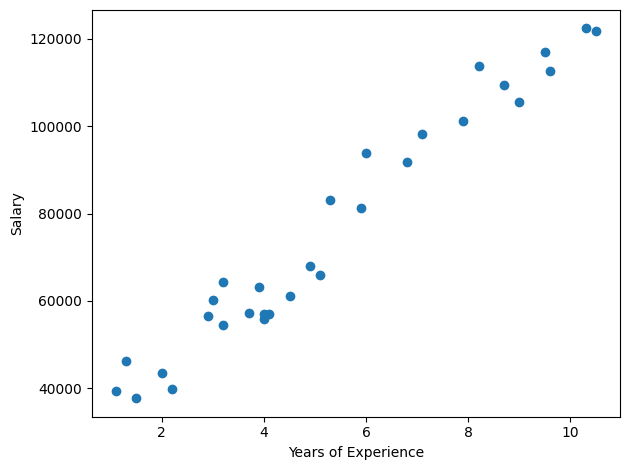

In [3]:
# Create a scatter plot to visualize the data trend
plt.scatter(x_train, y_train)
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.tight_layout()
plt.show()

In [5]:
def cost_function(x, y, w, b):
    m = len(x)
    
    # f(x) = wx + b
    f_wb = w * x + b
    
    # Cuadratic Error
    cost = np.sum((f_wb - y) ** 2) / (2 * m)
    
    return cost

In [10]:
def gradient_function(x, y, w, b):
    m = len(x)
    
    # Prediction vector and error vector
    f_wb = w*x + b
    error = f_wb - y
    
    # Derivative w: Dot product of the error and x
    dc_dw = np.dot(error, x) / m
    
    # Derivative b: Simple sum of the error vector
    dc_db = np.sum(error) / m
    
    return dc_dw, dc_db

In [11]:
def gradient_descent(x, y, alpha, iterations):
    # Gradient Descent Algorithm
    w = 0.0
    b = 0.0
    
    for i in range(iterations):
        dc_dw, dc_db = gradient_function(x, y, w, b)
        
        # Update parameters
        w = w - alpha * dc_dw
        b = b - alpha * dc_db
        
        if i % 1000 == 0:
            current_cost = cost_function(x, y, w, b)
            print(f"Iteration {i:5d}: Cost = {current_cost:.2f}")
                
    return w, b

In [15]:
# Parameters defined in the video
alpha = 0.001 # learning rate
iterations = 10000

# Run the algorithm
final_w, final_b = gradient_descent(x_train, y_train, alpha, iterations)

print(f"Final W (Slope): {final_w}")
print(f"Final B (Intercept): {final_b}")

Iteration     0: Cost = 3022091606.98
Iteration  1000: Cost = 55940335.55
Iteration  2000: Cost = 42035901.82
Iteration  3000: Cost = 32928241.45
Iteration  4000: Cost = 26962556.05
Iteration  5000: Cost = 23054922.16
Iteration  6000: Cost = 20495349.93
Iteration  7000: Cost = 18818782.95
Iteration  8000: Cost = 17720600.68
Iteration  9000: Cost = 17001271.05
Final W (Slope): 9876.972964280323
Final B (Intercept): 22914.688812206812


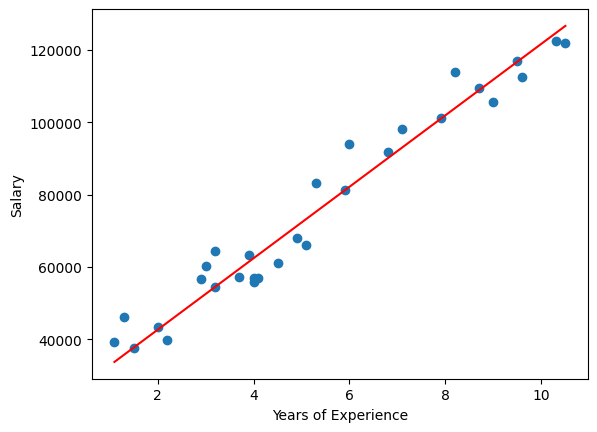

In [ ]:
# Plot the original points
plt.scatter(x_train, y_train)

# Draw the prediction line
plt.plot(x_train, final_w * x_train + final_b, color='red')

plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.tight_layout()
plt.show()